# Fast Differentiable Sorting & Ranking — étude expérimentale

**Projet CPU, autonome et reproductible** · Papier : Blondel, Teboul, Berthet & Djolonga (ICML 2020, arXiv:2002.08871v2).

### Question scientifique
> Peut-on obtenir des rangs à la fois fidèles, différentiables et efficaces ? Quelle est l'influence de la régularisation et de l'échelle des scores ?

Le notebook **implémente à partir des formules du papier** une projection sur le permutaèdre via l'algorithme PAV, ajoute une rétropropagation analytique, puis réalise quatre études :

1. Fidélité et gradients en fonction de $\varepsilon$ (quadratique / entropique).
2. Complexité pratique sur CPU : PAV vs comparaisons pairwise.
3. Extension : $\varepsilon$ adaptatif à l'échelle des scores.
4. Apprentissage d'un classement sur données synthétiques, avec plusieurs baselines.

**Reproductibilité :** graines fixées, tests mathématiques, résultats enregistrés dans `results/` (PNG + CSV). Les chiffres du PDF proviennent d'une exécution complète de ce code dans un environnement CPU et **varieront sur ta machine**.

**Installation (une seule fois) dans un terminal** : `python -m pip install numpy scipy pandas matplotlib torch ipykernel jupyter`. Aucun GPU/CUDA requis. Sous Windows, activer l'environnement Python souhaité avant `jupyter notebook`.


In [1]:
from pathlib import Path
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn.functional as F
from IPython.display import display, Image as NotebookImage

RESULTS = Path.cwd() / "results"
RESULTS.mkdir(parents=True, exist_ok=True)

def _outdir(outdir):
    path = Path(outdir) if outdir is not None else RESULTS
    path.mkdir(parents=True, exist_ok=True)
    return path

QUICK_MODE = False  # Passer à True pour une exécution raccourcie de l'apprentissage et du benchmark

torch.set_num_threads(min(torch.get_num_threads(), 4))
print("Device: CPU (CUDA non requis)")
print(f"NumPy: {np.__version__}, PyTorch: {torch.__version__}")
print(f"Répertoire des résultats : {RESULTS.resolve()}")


Device: CPU (CUDA non requis)
NumPy: 2.3.5, PyTorch: 2.10.0+cpu
Répertoire des résultats : /mnt/data/fast_soft_sort_study/notebook_validation/results


## 1. De la géométrie à une projection calculable

Pour un vecteur $w$, son **permutaèdre** est
$$\mathcal{P}(w)=\mathrm{conv}\{w_\sigma : \sigma\in\Sigma\}. $$

Le papier transforme le tri et le classement en problèmes d'optimisation sur ce polytope. Avec $\rho=(n,\dots,1)$, la régularisation quadratique conduit à :

$$r^Q_{\varepsilon}(\theta)=\operatorname{Proj}_{\mathcal P(\rho)}\big(-\theta/\varepsilon\big).$$

Une formule analogue donne le soft sort. Pour la variante entropique, on utilise une **projection KL dans l'espace exponentiel**, puis un logarithme.

La **Proposition 3** montre que ces projections se réduisent à la régression isotone. L'algorithme *Pool Adjacent Violators* (PAV) impose $v_1\geq\dots\geq v_n$ en fusionnant des blocs voisins. Après le tri en $O(n\log n)$, PAV est linéaire. Les dérivées sont calculées directement, sans rétropropager à travers toutes les itérations du solveur.

> Attention : *différentiable presque partout* ne signifie pas « gradient utile partout ». Un très petit $\varepsilon$ peut donner des gradients nuls sauf près des frontières de changement de classement.


In [2]:
"""Implémentation autonome de PAV, du permutaèdre et des soft ranks."""
from __future__ import annotations
from dataclasses import dataclass
import numpy as np
import torch


@dataclass
class ProjectionInfo:
    z_order: np.ndarray
    w_order: np.ndarray
    blocks: list[tuple[int, int]]
    s: np.ndarray
    w: np.ndarray
    regularization: str
    operation: str
    epsilon: float


def _validate(values, epsilon):
    arr = np.asarray(values, dtype=np.float64)
    if arr.ndim != 1:
        raise ValueError('Only a single 1D score vector is accepted by the NumPy routine.')
    if not np.all(np.isfinite(arr)):
        raise ValueError('The scores must be finite.')
    if not (np.isfinite(epsilon) and epsilon > 0):
        raise ValueError('epsilon must be finite and strictly positive.')
    return arr


def _pav_decreasing_quadratic(s, w):
    """Minimize sum_i (v_i - (s_i-w_i))^2/2 with v_1 >= ... >= v_n."""
    target = s - w
    stack = []  # [start, stop, sum, size]
    for i, t in enumerate(target):
        stack.append([i, i + 1, float(t), 1])
        while len(stack) > 1:
            left, right = stack[-2], stack[-1]
            if left[2] / left[3] >= right[2] / right[3]:
                break
            stack.pop(); stack.pop()
            stack.append([left[0], right[1], left[2] + right[2], left[3] + right[3]])
    v = np.empty_like(target)
    blocks = []
    for start, stop, total, size in stack:
        v[start:stop] = total / size
        blocks.append((start, stop))
    return v, blocks


def _pav_decreasing_entropic(s, w):
    """Minimize <exp(s-v),1>+<exp(w),v> under v_1 >= ... >= v_n."""
    stack = []  # [start, stop, logsumexp(s_block), logsumexp(w_block)]
    for i, (si, wi) in enumerate(zip(s, w)):
        stack.append([i, i + 1, float(si), float(wi)])
        while len(stack) > 1:
            left, right = stack[-2], stack[-1]
            if left[2] - left[3] >= right[2] - right[3]:
                break
            stack.pop(); stack.pop()
            stack.append([left[0], right[1],
                          float(np.logaddexp(left[2], right[2])),
                          float(np.logaddexp(left[3], right[3]))])
    v = np.empty_like(s)
    blocks = []
    for start, stop, lse_s, lse_w in stack:
        v[start:stop] = lse_s - lse_w
        blocks.append((start, stop))
    return v, blocks


def hard_rank(theta):
    """Descending ranks, 1 for highest; stable rule for ties."""
    x = np.asarray(theta)
    order = np.argsort(-x, kind='stable')
    result = np.empty(len(x), dtype=np.int64)
    result[order] = np.arange(1, len(x) + 1)
    return result


def soft_order_numpy(theta, epsilon=1., operation='rank', regularization='quadratic', return_info=False):
    """Project with Proposition 3. O(n log n) sort + O(n) stack PAV, O(n) memory.

    operation='rank': P_Psi(-theta/eps, rho)
    operation='sort': P_Psi(rho/eps, theta)
    The entropic P is the LOG of a KL projection of exponentiated scores.
    """
    theta = _validate(theta, epsilon)
    if operation not in ('rank', 'sort'):
        raise ValueError("operation must be 'rank' or 'sort'.")
    if regularization not in ('quadratic', 'entropic'):
        raise ValueError("regularization must be 'quadratic' or 'entropic'.")
    n = len(theta)
    rho = np.arange(n, 0, -1, dtype=np.float64)
    if operation == 'rank':
        z, w = -theta / epsilon, rho
    else:
        z, w = rho / epsilon, theta
    z_order = np.argsort(-z, kind='stable')
    w_order = np.argsort(-w, kind='stable')
    s, sorted_w = z[z_order], w[w_order]
    if regularization == 'quadratic':
        v, blocks = _pav_decreasing_quadratic(s, sorted_w)
    else:
        v, blocks = _pav_decreasing_entropic(s, sorted_w)
    y_sorted = s - v
    result = np.empty(n, dtype=np.float64)
    result[z_order] = y_sorted
    info = ProjectionInfo(z_order, w_order, blocks, s, sorted_w, regularization, operation, float(epsilon))
    return (result, info) if return_info else result




### Différentiation analytique

Dans un bloc PAV $B$ de longueur $|B|$, le Jacobien de la solution isotone est simple :

- **Quadratique** : moyenne uniforme des coordonnées du bloc.
- **Entropique** : moyenne pondérée par un softmax, pour la dérivée en fonction des scores.

Nous construisons un `torch.autograd.Function` : le passage avant est calculé en NumPy, le passage arrière applique directement le produit vecteur-Jacobien en $O(n)$, sans former de matrice dense.


In [3]:
def _weights(values):
    values = np.asarray(values, dtype=np.float64)
    vals = np.exp(values - np.max(values))
    return vals / vals.sum()


def _vjp_numpy(info: ProjectionInfo, grad_output):
    """Efficient vector-Jacobian product: no n x n matrix is formed."""
    gout = np.asarray(grad_output, dtype=np.float64)
    n = len(gout)
    g_sorted = gout[info.z_order]
    grad = np.zeros(n)
    for begin, end in info.blocks:
        g = g_sorted[begin:end]
        if info.operation == 'rank':
            if info.regularization == 'quadratic':
                # (I-B)^T g = g - mean(g), with B_ij = 1/|block|
                grad[begin:end] = g - np.mean(g)
            else:
                # B_ij = softmax(s)_j, hence B^T g = softmax(s) * sum(g)
                grad[begin:end] = g - _weights(info.s[begin:end]) * np.sum(g)
        else:
            # d soft_sort/d w_sorted = B_w; its VJP is B_w^T g.
            if info.regularization == 'quadratic':
                grad[begin:end] = np.mean(g)
            else:
                grad[begin:end] = _weights(info.w[begin:end]) * np.sum(g)
    original = np.empty_like(grad)
    if info.operation == 'rank':
        original[info.z_order] = -grad / info.epsilon
    else:
        original[info.w_order] = grad
    return original


class _TorchSoftOrder(torch.autograd.Function):
    @staticmethod
    def forward(ctx, theta, epsilon: float, operation: str, regularization: str):
        if theta.ndim not in (1, 2):
            raise ValueError('theta must be [n] or [batch, n].')
        was_1d = (theta.ndim == 1)
        x = theta.detach().cpu().double().numpy()
        if was_1d:
            x = x[None, :]
        result, infos = [], []
        for row in x:
            val, info = soft_order_numpy(row, epsilon, operation, regularization, True)
            result.append(val)
            infos.append(info)
        ctx.infos = infos
        ctx.was_1d = was_1d
        output = torch.as_tensor(np.stack(result), device=theta.device, dtype=theta.dtype)
        return output[0] if was_1d else output

    @staticmethod
    def backward(ctx, grad_output):
        grad = grad_output.detach().cpu().double().numpy()
        if ctx.was_1d:
            grad = grad[None, :]
        inputs = np.stack([_vjp_numpy(info, gout) for info, gout in zip(ctx.infos, grad)])
        result = torch.as_tensor(inputs, dtype=grad_output.dtype, device=grad_output.device)
        return (result[0] if ctx.was_1d else result), None, None, None


def soft_order_torch(theta, epsilon=1., operation='rank', regularization='quadratic'):
    """Autograd wrapper, CPU-oriented educational implementation (forward/backward exact a.e.)."""
    return _TorchSoftOrder.apply(theta, float(epsilon), operation, regularization)


def all_pairs_soft_rank(theta, temperature=0.5):
    """Vectorized O(n^2) comparison baseline; same descending-rank convention."""
    theta = np.asarray(theta, dtype=np.float64)
    if temperature <= 0:
        raise ValueError('temperature must be > 0')
    diff = (theta[None, :] - theta[:, None]) / temperature
    # sigmoid without scipy; clipping is only for numerical stability
    probs = 1.0 / (1.0 + np.exp(-np.clip(diff, -60., 60.)))
    return 0.5 + probs.sum(axis=1)


## 2. Vérifications mathématiques avant les expériences

Nous validons la projection quadratique par comparaison avec un solveur contraint indépendant en petite dimension. Nous comparons ensuite les gradients PyTorch à des différences finies, en des points sans changement de structure PAV. Ce sont des contrôles de cohérence, non une preuve formelle du théorème.

In [4]:
from scipy.optimize import minimize
from itertools import combinations

def independent_qp(z, w):
    """Projection euclidienne sur P(w), avec contraintes de majorisation (n <= 4)."""
    n = len(w)
    w_sorted = np.sort(w)[::-1]
    constraints = [{'type': 'eq', 'fun': lambda y: np.sum(y) - np.sum(w),
                    'jac': lambda y: np.ones(n)}]
    for k in range(1, n):
        bound = w_sorted[:k].sum()
        for idx in combinations(range(n), k):
            a = np.zeros(n); a[list(idx)] = 1
            constraints.append({'type':'ineq',
                                'fun': lambda y, a=a, bound=bound: bound - a @ y,
                                'jac': lambda y, a=a: -a})
    sol = minimize(lambda y: 0.5*np.sum((y-z)**2),
                   np.full(n, np.mean(w)), jac=lambda y: y-z, method='SLSQP',
                   constraints=constraints, options={'ftol':1e-10, 'maxiter':1000})
    assert sol.success, sol.message
    return sol.x

x = np.array([1.7, -0.2, 0.8, 2.1])
rho = np.arange(len(x), 0, -1, dtype=float)
checks = 0
for op in ('rank', 'sort'):
    for eps in (0.05, 0.25, 2.0):
        z,w = (-x/eps, rho) if op == 'rank' else (rho/eps, x)
        np.testing.assert_allclose(soft_order_numpy(x,eps,op,'quadratic'),
                                   independent_qp(z,w), atol=1e-5)
        checks += 1

for op in ('rank','sort'):
    for reg in ('quadratic','entropic'):
        v = np.array([0.1, 0.7, -0.3, 1.2, -0.6])
        weights = np.array([.2,-.4,.8,-.1,.3])
        xt = torch.tensor(v, dtype=torch.float64, requires_grad=True)
        (soft_order_torch(xt,0.7,op,reg)*torch.tensor(weights)).sum().backward()
        grad_fd = np.empty(len(v))
        for i in range(len(v)):
            plus,minus=v.copy(),v.copy()
            plus[i]+=1e-6; minus[i]-=1e-6
            grad_fd[i] = np.dot(weights,
                              soft_order_numpy(plus,.7,op,reg)-soft_order_numpy(minus,.7,op,reg))/2e-6
        np.testing.assert_allclose(xt.grad.numpy(),grad_fd,rtol=5e-5,atol=5e-5)
        checks += 1
print(f"Tests intégrés : {checks} contrôles réussis (QP + gradients).")


Tests intégrés : 10 contrôles réussis (QP + gradients).


## 3. Expérience 1 — Fidélité des rangs et signal de gradient

**Hypothèse.** Quand $\varepsilon\rightarrow0$, les soft ranks se rapprochent des hard ranks. Mais l'intensité des gradients n'évolue pas nécessairement de manière monotone : elle dépend des blocs PAV et des écarts entre scores.

**Protocole.** Vecteur aléatoire de $n=24$ scores ; cible de classement perturbée ; balayage logarithmique de $\varepsilon$ ; comparaison des régularisations Q/E. Indicateurs : erreur MAE des rangs, norme du gradient de MSE, proportion de coordonnées appartenant à un bloc PAV non singleton.

**Lecture critique.** La norme du gradient mesure son amplitude, **pas sa qualité directionnelle**. Le graphique ne prouve pas qu'une valeur de $\varepsilon$ entraîne mieux un réseau.


In [5]:
def experiment_gradient_tradeoff(outdir=None, seed=23):
    """Forward MAE, gradient norm, and PAV block density vs epsilon."""
    p=_outdir(outdir)
    rng=np.random.default_rng(seed)
    n=24
    theta=rng.normal(size=n)
    hard=hard_rank(theta)
    # A nontrivial (disagreeing) target: hard rank loss is > 0 but flat a.e.
    target=hard_rank(theta+0.8*rng.normal(size=n)).astype(float)
    eps_grid=np.geomspace(0.002,40,33)
    rows=[]
    for reg in ('quadratic','entropic'):
        for eps in eps_grid:
            soft, info=soft_order_numpy(theta,eps,'rank',reg,True)
            x=torch.tensor(theta,dtype=torch.float64,requires_grad=True)
            y=soft_order_torch(x,eps,'rank',reg)
            loss=((y-torch.as_tensor(target))**2).mean()
            loss.backward()
            grad=float(x.grad.norm().item())
            nonsingle=sum((end-begin) for begin,end in info.blocks if end-begin>=2)
            rows.append({'regularization':reg,'epsilon':eps,
                         'rank_MAE':np.mean(np.abs(soft-hard)),
                         'loss_to_target':loss.item(),
                         'gradient_norm':grad,
                         'fraction_non_singleton':nonsingle/n,
                         'number_blocks':len(info.blocks)})
    df=pd.DataFrame(rows)
    df.to_csv(p/'01_gradient_tradeoff.csv',index=False)
    fig,axs=plt.subplots(1,3,figsize=(13.5,3.7))
    for reg,label in [('quadratic','Quadratic (Q)'),('entropic','Entropic (E)')]:
        d=df[df.regularization==reg]
        axs[0].semilogx(d.epsilon,d.rank_MAE,marker='.',label=label)
        axs[1].semilogx(d.epsilon,d.gradient_norm,marker='.',label=label)
        axs[2].semilogx(d.epsilon,d.fraction_non_singleton,marker='.',label=label)
    axs[0].set_title('Fidelity to hard ranks')
    axs[0].set_ylabel('Mean absolute rank error')
    axs[1].set_title('Learning signal')
    axs[1].set_ylabel('Norm of gradient of rank MSE')
    axs[2].set_title('PAV block formation')
    axs[2].set_ylabel('Fraction of coordinates in multi-point blocks')
    for a in axs:
        a.set_xlabel('Regularization ε')
        a.grid(True,alpha=.2)
    axs[0].legend(frameon=False)
    fig.suptitle('Experiment 1 — Approximation versus useful gradients',y=1.04,fontsize=13)
    fig.tight_layout()
    fig.savefig(p/'01_gradient_tradeoff.png',dpi=180,bbox_inches='tight')
    plt.close(fig)
    return df




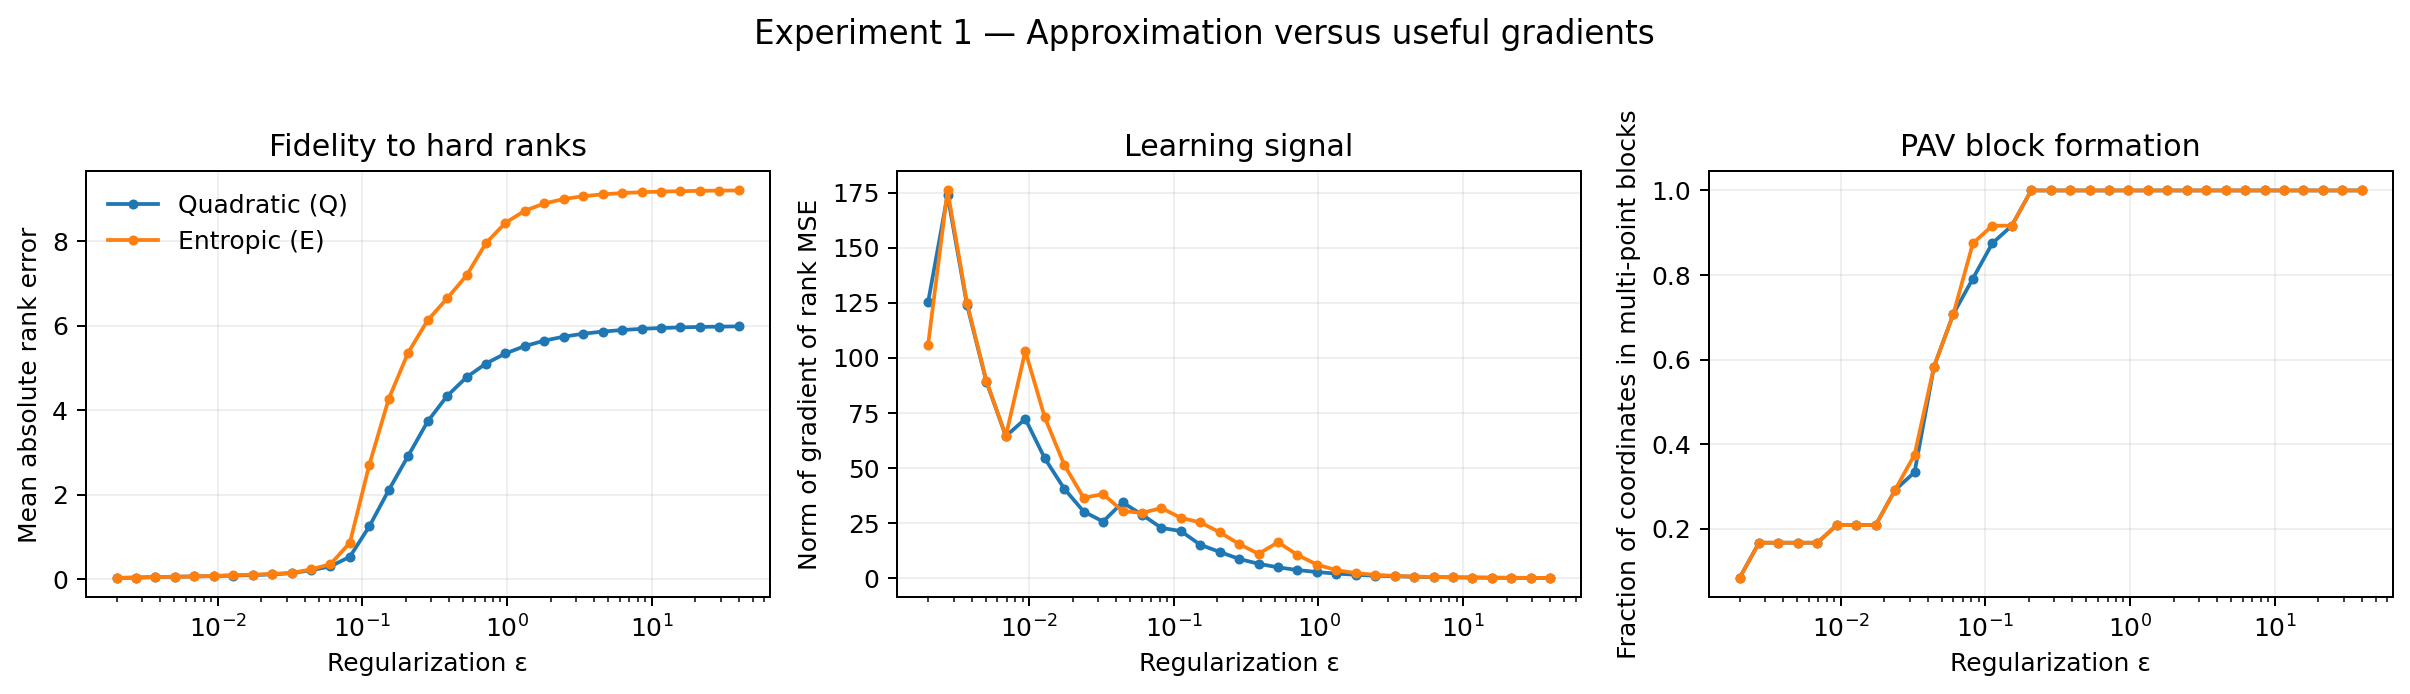

rank_MAE        gradient_norm         
                    min    max           min      max
regularization                                       
entropic          0.031  9.200         0.072  175.984
quadratic         0.031  5.984         0.071  173.837

In [6]:
df_gradient = experiment_gradient_tradeoff(RESULTS)
display(NotebookImage(filename=str(RESULTS/'01_gradient_tradeoff.png')))
display(df_gradient.groupby('regularization')[['rank_MAE','gradient_norm']].agg(['min','max']).round(3))


## 4. Expérience 2 — Temps de calcul et mémoire sur CPU

**Hypothèse.** La méthode PAV $O(n\log n)$ doit mieux passer à l'échelle que la baseline *All-pairs sigmoid* $O(n^2)$ ; en faible dimension, la vectorisation NumPy peut inverser l'avantage.

**Protocole.** Temps médian du passage avant d'un **seul** vecteur, CPU, mêmes scores et mêmes dimensions. Le calcul mémoire est un **minorant analytique** pour une seule matrice pairwise float64, et non une mesure instrumentée de mémoire maximale.

**Limite.** Comparaison d'implémentations pédagogiques NumPy, **pas** un benchmark officiel GPU de l'article, ni une comparaison de backpropagation complète.


In [7]:
def experiment_benchmark(outdir=None, seed=2, repeats=7):
    """Pure NumPy *forward only* CPU timing, not GPU or training benchmarks."""
    p=_outdir(outdir)
    rng=np.random.default_rng(seed)
    dims=[32,64,128,256,512,1024,2048,4096]
    rows=[]
    for n in dims:
        theta=rng.normal(size=n)
        for method,func in [
            ('PAV quadratic',lambda:soft_order_numpy(theta,0.3,'rank','quadratic')),
            ('PAV entropic',lambda:soft_order_numpy(theta,0.3,'rank','entropic')),
            ('All-pairs sigmoid',lambda:all_pairs_soft_rank(theta,temperature=.3))
        ]:
            func()  # warm-up; not timed
            times=[]
            for _ in range(repeats):
                start=time.perf_counter()
                func()
                times.append((time.perf_counter()-start)*1e3)
            rows.append({'n':n,'method':method,'median_ms':np.median(times),
                         'min_ms':np.min(times),'repeats':repeats,
                         'pairwise_single_matrix_MiB':8*n*n/2**20})
    df=pd.DataFrame(rows)
    df.to_csv(p/'02_benchmark.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(10.5,3.6))
    for method, d in df.groupby('method',sort=False):
        axs[0].loglog(d.n,d.median_ms,'o-',label=method)
    axs[0].set_title('Forward pass, single vector, CPU')
    axs[0].set_xlabel('Vector dimension n')
    axs[0].set_ylabel('Median time (ms, log scale)')
    axs[0].grid(True,which='both',alpha=.2)
    axs[0].legend(fontsize=8,frameon=False)
    dims=np.asarray(dims)
    axs[1].loglog(dims,8*dims**2/2**20,'o-',label='One n×n float64 matrix')
    axs[1].set_title('Pairwise memory lower bound')
    axs[1].set_xlabel('Vector dimension n')
    axs[1].set_ylabel('MiB, one matrix only')
    axs[1].grid(True,which='both',alpha=.2)
    axs[1].legend(fontsize=8,frameon=False)
    fig.suptitle('Experiment 2 — Scaling and computational trade-offs',y=1.04,fontsize=13)
    fig.tight_layout()
    fig.savefig(p/'02_benchmark.png',dpi=180,bbox_inches='tight')
    plt.close(fig)
    return df




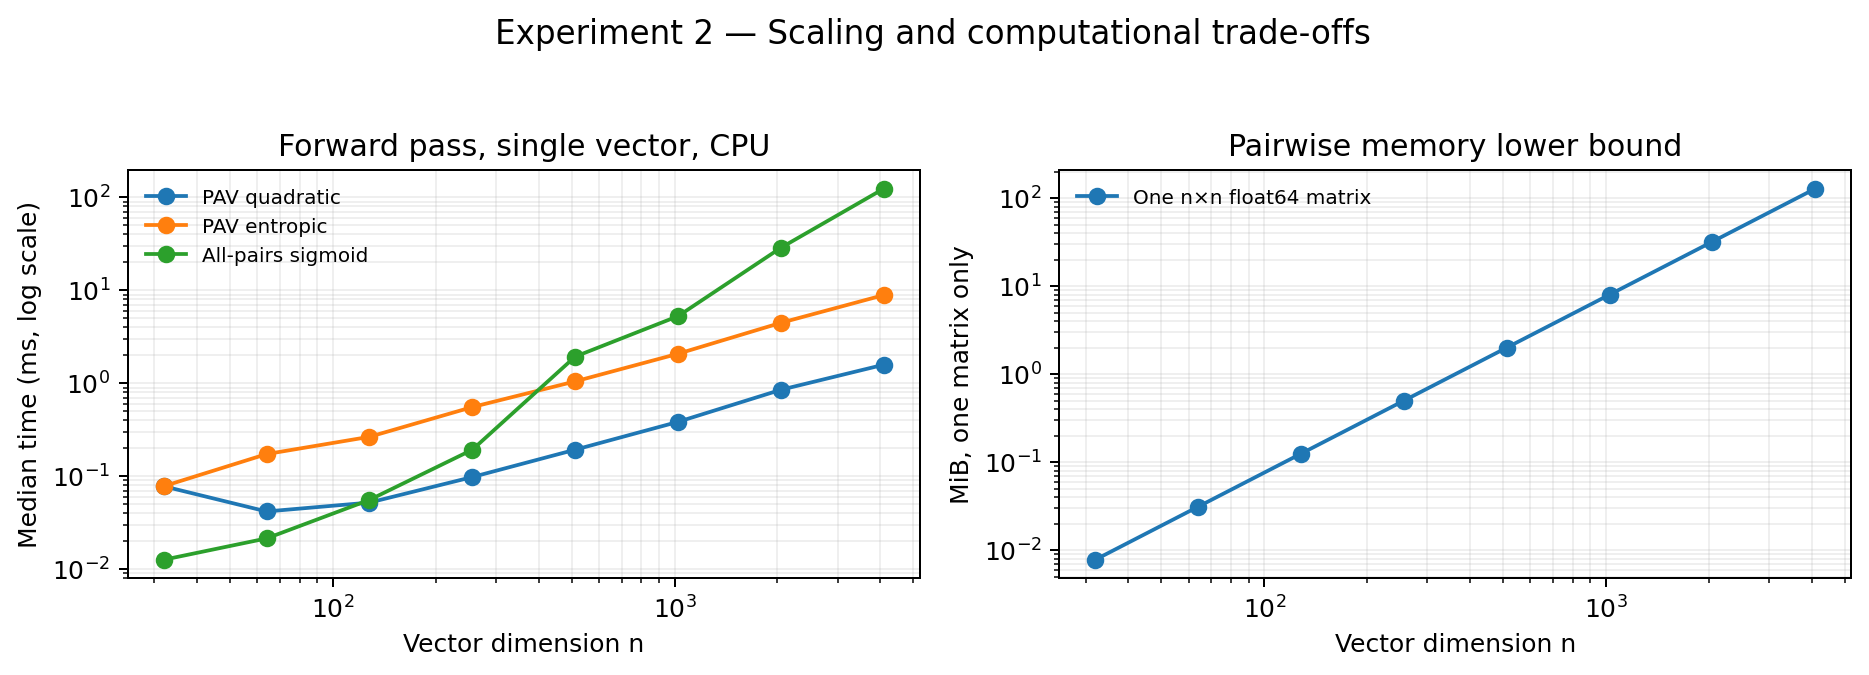

method,All-pairs sigmoid,PAV entropic,PAV quadratic
n,,,
32,0.013,0.078,0.078
64,0.021,0.173,0.042
128,0.056,0.266,0.052
256,0.193,0.555,0.098
512,1.937,1.049,0.193
1024,5.279,2.079,0.385
2048,28.751,4.477,0.852
4096,124.355,8.899,1.585


In [8]:
df_speed = experiment_benchmark(RESULTS, repeats=3 if QUICK_MODE else 7)
display(NotebookImage(filename=str(RESULTS/'02_benchmark.png')))
display(df_speed.pivot(index='n', columns='method', values='median_ms').round(3))


## 5. Expérience 3 — Notre extension : régularisation dépendant de l'échelle

**Problème.** À classement inchangé, multiplier tous les logits par $c>0$ modifie le soft ranking si $\varepsilon$ reste constant.

Comme $r^Q_\varepsilon(c\theta)=r^Q_{\varepsilon/c}(\theta)$, choisir
$$\varepsilon(\theta)=\alpha\,\operatorname{std}(\theta)$$
rend la sortie invariante aux changements positifs d'échelle (si l'écart-type n'est pas nul). On obtient aussi l'invariance par translation. La variante entropique possède la même propriété de rééchelonnement de l'entrée $-\theta/\varepsilon$.

**Mise en œuvre pendant l'entraînement.** Nous normalisons $\theta$ avec des **opérations PyTorch différentiables** avant d'appliquer l'opérateur avec $\varepsilon=\alpha$. La dépendance de $\varepsilon$ aux scores participe donc à la chaîne de dérivation. Le `clamp_min` protège les vecteurs quasi constants, mais limite l'invariance exacte dans cette région.

**Portée.** C'est une proposition de protocole et de normalisation, pas la revendication d'un théorème nouveau.


In [9]:
def adaptive_soft_rank(theta:torch.Tensor, alpha:float=0.4, regularization='quadratic'):
    """Affine-invariant-in-exact-arithmetic soft ranking with chain-rule gradients.

    Normalize scores with *torch ops* so autograd accounts for the dependence
    epsilon(theta). Do not detach std: that would compute an incomplete gradient.
    For constant/near-constant rows clamp prevents divide-by-zero, so strict
    scale invariance is only assured outside the clamp region.
    """
    if theta.ndim not in (1,2):
        raise ValueError('Expected [n] or [batch,n]')
    centered=theta-theta.mean(dim=-1,keepdim=True)
    std=centered.square().mean(dim=-1,keepdim=True).sqrt().clamp_min(1e-8)
    return soft_order_torch(centered/std,alpha,'rank',regularization)


def experiment_adaptive_epsilon(outdir=None, seed=31):
    """Investigate positive-scale invariance; not a novel theorem."""
    p=_outdir(outdir)
    rng=np.random.default_rng(seed)
    theta=rng.normal(size=24)
    alpha=0.4
    eps0=alpha*theta.std()
    scales=np.geomspace(0.02,50,33)
    rows=[]
    for reg in ('quadratic','entropic'):
        reference=soft_order_numpy(theta,eps0,'rank',reg)
        for c in scales:
            fixed=soft_order_numpy(c*theta,eps0,'rank',reg)
            adapted=soft_order_numpy(c*theta,c*eps0,'rank',reg)
            rows.append({'regularization':reg,'scale':c,
                         'fixed_displacement':np.abs(fixed-reference).mean(),
                         'adaptive_displacement':np.abs(adapted-reference).mean(),
                         'std_epsilon':alpha*np.std(c*theta)})
    df=pd.DataFrame(rows)
    df.to_csv(p/'03_scale_invariance.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(10.5,3.6))
    for a,reg in zip(axs,('quadratic','entropic')):
        d=df[df.regularization==reg]
        a.semilogx(d.scale,d.fixed_displacement,'o-',ms=3,label='Fixed ε')
        a.semilogx(d.scale,d.adaptive_displacement,'o-',ms=3,label='ε = α · std(scores)')
        a.set_title(f'{reg.title()} soft ranking')
        a.set_xlabel('Score multiplier c')
        a.set_ylabel('MAE against soft rank at c = 1')
        a.grid(True,alpha=.2)
        a.legend(fontsize=8,frameon=False)
    fig.suptitle('Experiment 3 — Handling score rescaling',y=1.04,fontsize=13)
    fig.tight_layout()
    fig.savefig(p/'03_scale_invariance.png',dpi=180,bbox_inches='tight')
    plt.close(fig)
    return df




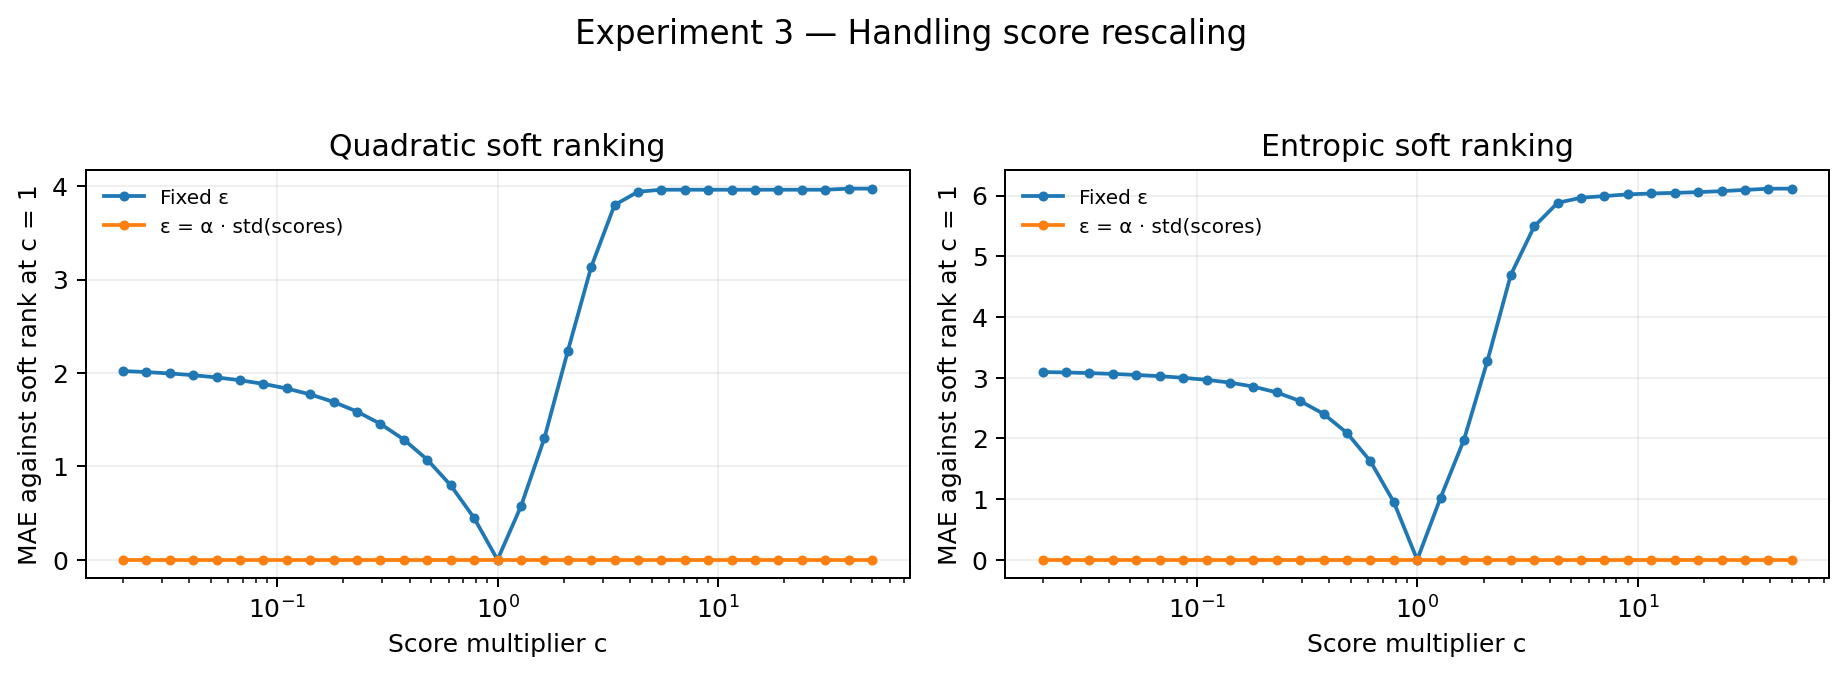

,fixed_displacement,adaptive_displacement
regularization,,
entropic,6.113653,5.181041e-16
quadratic,3.973085,3.700743e-16


In [10]:
df_scale = experiment_adaptive_epsilon(RESULTS)
display(NotebookImage(filename=str(RESULTS/'03_scale_invariance.png')))
display(df_scale.groupby('regularization')[['fixed_displacement','adaptive_displacement']].max())


## 6. Expérience 4 — Apprendre des classements de bout en bout

**Question.** Le signal issu du soft ranking permet-il effectivement d'ajuster des paramètres ?

**Protocole.** Jeu synthétique : modèle enseignant linéaire de 10 variables vers 8 classes ; 700 exemples d'apprentissage avec perturbation des scores ; 300 exemples de test **sans bruit**. Régression linéaire PyTorch entraînée avec le même budget de pas d'optimisation. Moyenne de corrélation de Spearman des rangs *hard* sur le jeu test.

Baselines : MSE sur des rangs normalisés par centrage (`raw_rank_mse`, sans couche soft), et perte logistique pairwise. Les noms ne doivent pas être confondus : la perte pairwise de l'expérience 4 n'est pas exactement l'opérateur sigmoid All-pairs de l'expérience 2.

**Important.** Comparaison illustrative sur un problème favorable à un modèle linéaire. Les résultats ne prouvent pas une supériorité statistique sur des données réelles.


In [11]:
def rank_batch(scores:np.ndarray):
    """Descending hard ranks for a batch, ties deterministically resolved."""
    scores=np.asarray(scores)
    order=np.argsort(-scores,axis=1,kind='stable')
    out=np.empty(order.shape,dtype=np.int64)
    out[np.arange(len(scores))[:,None],order]=np.arange(1,scores.shape[1]+1)
    return out


def spearman_batch(pred:np.ndarray,target:np.ndarray):
    """Mean Spearman rho for full rankings without ties."""
    pr=rank_batch(pred)
    n=pred.shape[1]
    rho=1-6*np.sum((pr-target)**2,axis=1)/(n*(n*n-1))
    return float(rho.mean())


def experiment_learning(outdir=None, seeds=(0,1,2), steps=210, batch_size=64):
    """Label-ranking *synthetic* study with an independent latent teacher.

    Same model (linear) and optimizer budget for all learning objectives.
    Pairwise logistic is an established baseline, not the paper's all-pairs
    sigmoid operator. Scores are evaluated by HARD rank on clean holdout labels.
    """
    p=_outdir(outdir)
    results=[]
    histories=[]
    for seed in seeds:
        torch.manual_seed(int(seed))
        rng=np.random.default_rng(int(seed))
        d,nlabels,ntrain,ntest=10,8,700,300
        teacher=rng.normal(size=(d,nlabels))/np.sqrt(d)
        X_train=rng.normal(size=(ntrain,d))
        X_test=rng.normal(size=(ntest,d))
        # Noise in TRAIN rankings only, clean teacher ranking at test.
        train_rank=rank_batch(X_train @ teacher + .25*rng.normal(size=(ntrain,nlabels)))
        test_rank=rank_batch(X_test @ teacher)
        x_train=torch.tensor(X_train,dtype=torch.float32)
        r_train=torch.tensor(train_rank,dtype=torch.float32)
        i,j=np.triu_indices(nlabels,k=1)
        for method in ('soft_fixed','soft_adaptive','pairwise_logistic','raw_rank_mse'):
            # Re-initialize *identically* to ensure a controlled comparison.
            torch.manual_seed(int(seed)+1000)
            model=torch.nn.Linear(d,nlabels,bias=False)
            with torch.no_grad():
                model.weight.mul_(0.4)
            optimizer=torch.optim.Adam(model.parameters(),lr=.035)
            initial=spearman_batch(model(torch.tensor(X_test,dtype=torch.float32)).detach().numpy(),test_rank)
            for step in range(1,steps+1):
                indices=torch.randint(0,ntrain,(batch_size,))
                scores=model(x_train[indices])
                gt=r_train[indices]
                if method=='soft_fixed':
                    soft=soft_order_torch(scores,0.45,'rank','quadratic')
                    loss=((soft-gt)**2).mean()
                elif method=='soft_adaptive':
                    soft=adaptive_soft_rank(scores,0.45,'quadratic')
                    loss=((soft-gt)**2).mean()
                elif method=='pairwise_logistic':
                    # +1 if class i must have a better score than class j
                    signs=torch.sign(gt[:,j]-gt[:,i])
                    dif=scores[:,i]-scores[:,j]
                    loss=F.softplus(-signs*dif).mean()
                else:
                    # Simple score regression baseline, WITHOUT a soft rank layer.
                    centered_target=gt.mean(dim=1,keepdim=True)-gt
                    loss=((scores-centered_target)**2).mean()
                optimizer.zero_grad(set_to_none=True)
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(),10.0)
                optimizer.step()
                if step%30==0 or step==1 or step==steps:
                    with torch.no_grad():
                        test_scores=model(torch.tensor(X_test,dtype=torch.float32)).numpy()
                    corr=spearman_batch(test_scores,test_rank)
                    histories.append({'seed':seed,'method':method,'step':step,
                                      'test_spearman':corr,'train_objective':loss.item()})
            final=spearman_batch(model(torch.tensor(X_test,dtype=torch.float32)).detach().numpy(),test_rank)
            results.append({'seed':seed,'method':method,'initial_spearman':initial,
                            'final_spearman':final,'steps':steps})
    df=pd.DataFrame(results)
    hist=pd.DataFrame(histories)
    df.to_csv(p/'04_learning_summary.csv',index=False)
    hist.to_csv(p/'04_learning_history.csv',index=False)
    fig,axs=plt.subplots(1,2,figsize=(11,3.9))
    for method,part in hist.groupby('method',sort=False):
        curve=part.groupby('step').test_spearman.agg(['mean','std']).reset_index()
        std=curve['std'].fillna(0)
        axs[0].plot(curve.step,curve['mean'],marker='.',label=method)
        axs[0].fill_between(curve.step,curve['mean']-std,curve['mean']+std,alpha=.08)
    axs[0].set_title('Test rank correlation during learning')
    axs[0].set_xlabel('Optimizer steps')
    axs[0].set_ylabel('Mean Spearman ρ (clean holdout)')
    axs[0].grid(True,alpha=.2)
    axs[0].legend(fontsize=7,frameon=False)
    summary=df.groupby('method').final_spearman.agg(['mean','std']).sort_values('mean',ascending=False)
    names=summary.index.tolist()
    axs[1].barh(names[::-1],summary['mean'].to_numpy()[::-1],xerr=summary['std'].to_numpy()[::-1],capsize=3)
    axs[1].set_xlim(-.1,1.0)
    axs[1].set_xlabel('Mean Spearman ρ ± std across seeds')
    axs[1].set_title('Final performance (3 synthetic seeds)')
    axs[1].grid(True,axis='x',alpha=.2)
    fig.suptitle('Experiment 4 — End-to-end training of label rankings',y=1.04,fontsize=13)
    fig.tight_layout()
    fig.savefig(p/'04_learning.png',dpi=180,bbox_inches='tight')
    plt.close(fig)
    return df,hist




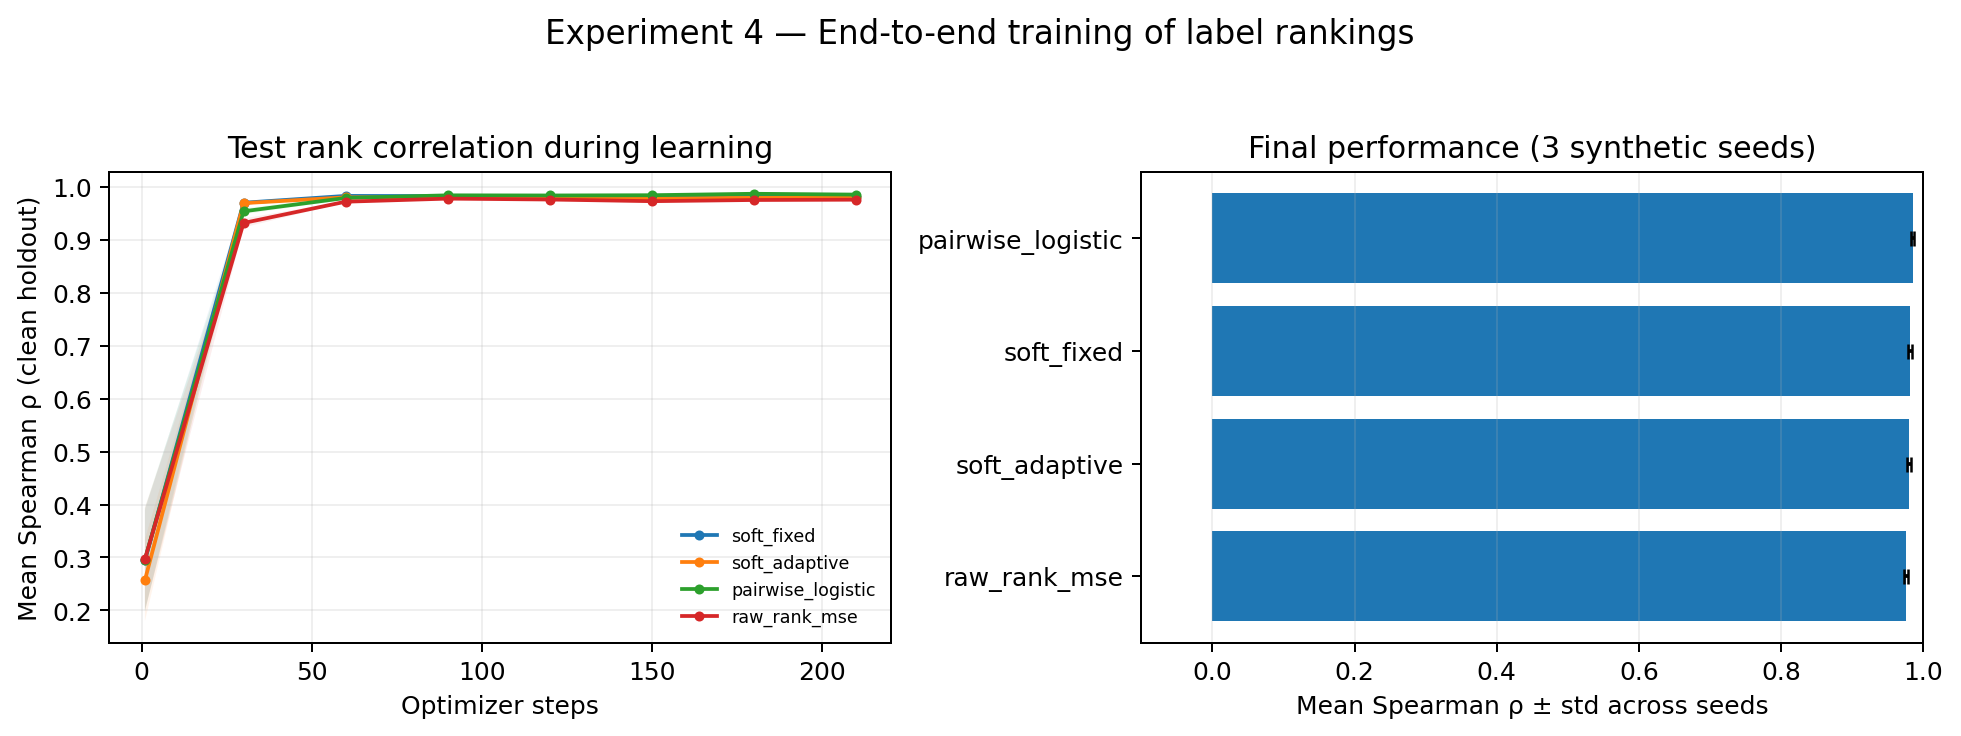

,mean,std
method,,
pairwise_logistic,0.9852,0.0023
raw_rank_mse,0.9756,0.0026
soft_adaptive,0.9798,0.0031
soft_fixed,0.9808,0.0030


In [12]:
df_learning, history = experiment_learning(
    RESULTS,
    seeds=(0,) if QUICK_MODE else (0,1,2),
    steps=90 if QUICK_MODE else 210,
    batch_size=64)
display(NotebookImage(filename=str(RESULTS/'04_learning.png')))
display(df_learning.groupby('method').final_spearman.agg(['mean','std']).round(4))


## 7. Synthèse automatique et pistes d'analyse

Les conclusions doivent s'appuyer sur les chiffres **produits localement**. Le programme ci-dessous synthétise le point de bascule des temps de calcul, l'invariance obtenue et la performance finale de chaque méthode. Lorsque `QUICK_MODE=True`, les comparaisons de performance entre méthodes sont surtout exploratoires.

In [13]:
pivot = df_speed.pivot(index='n',columns='method',values='median_ms')
indices = pivot.index[pivot['PAV quadratic'] < pivot['All-pairs sigmoid']]
first_crossover = int(indices.min()) if len(indices) else None
largest = int(pivot.index.max())
ratio = pivot.loc[largest,'All-pairs sigmoid']/pivot.loc[largest,'PAV quadratic']
max_dev = float(df_scale['adaptive_displacement'].max())
print(f"Premier n mesuré où PAV quadratique est plus rapide : {first_crossover}")
print(f"A n={largest}, ratio pairwise/PAV quadratique : {ratio:.1f}x")
print(f"Écart max après adaptation d'échelle : {max_dev:.2e}")
print("Spearman moyen au test (ordre décroissant) :")
print(df_learning.groupby('method').final_spearman.mean().sort_values(ascending=False).to_string())
print("\nLecture : fidélité, gradients, temps CPU et qualité prédictive sont des critères DISTINCTS.")
print("Tous les CSV et les PNG sont dans", RESULTS.resolve())


Premier n mesuré où PAV quadratique est plus rapide : 128
A n=4096, ratio pairwise/PAV quadratique : 78.5x
Écart max après adaptation d'échelle : 5.18e-16
Spearman moyen au test (ordre décroissant) :
method
pairwise_logistic    0.985238
soft_fixed           0.980794
soft_adaptive        0.979815
raw_rank_mse         0.975608

Lecture : fidélité, gradients, temps CPU et qualité prédictive sont des critères DISTINCTS.
Tous les CSV et les PNG sont dans /mnt/data/fast_soft_sort_study/notebook_validation/results


## 8. Discussions et limites à considérer pour votre présentation

- **Pourquoi PAV ?** Le coût $O(n\log n)$ vient du tri et la passe PAV est linéaire. Le Jacobien peut être appliqué sans stocker une matrice dense.
- **Pourquoi la performance ne suit-elle pas directement la complexité ?** La baseline $O(n^2)$ est vectorisée NumPy ; le PAV présenté ici utilise une pile Python. Les résultats dépendent du matériel et de l'implémentation.
- **Comment interpréter un $\varepsilon$ trop faible ou trop élevé ?** Très faible : fonctions proches du rang dur, mais gradients fortement localisés. Très élevé : perte d'information de classement, norme des gradients tendant vers zéro ; pour l'entropie, la limite constante **n'est pas** nécessairement le rang moyen.
- **Qu'apporte la normalisation ?** Invariance à la translation et à l'échelle des scores pour les vecteurs non constants ; cela ne garantit pas de meilleurs résultats d'apprentissage.
- **Quelles améliorations scientifiques possibles ?** Répéter sur des distributions de scores différentes, des niveaux de bruit variés, 10+ graines, et mesurer le temps de *backward* et la mémoire crête, idéalement sur CPU **et** GPU si le matériel est disponible.

**Référence principale :** M. Blondel, O. Teboul, Q. Berthet, J. Djolonga, *Fast Differentiable Sorting and Ranking*, ICML 2020, https://arxiv.org/abs/2002.08871. L'implémentation ci-dessus est autonome et pédagogique, non identique à la bibliothèque optimisée des auteurs.
